# 03 - Antibiotic killing and dose: γ, h_a, a0

**Question.** How do the maximum lysis strength (γ), the steepness of the antibiotic's
dose response (h_a) and the dose itself (a0) shape the crash, the recovery and the final composition?
These three set the lysis term l = γ · a^h_a/(1 + a^h_a) · g.

**Sweep.** 22 × 21 × 22 = 10,164 runs: 21 evenly spaced values per parameter (a0 log-spaced over the
paper's dose range 1-100), plus the base values γ = 1.38 and a0 = 2.15, which do not fall on the
21-point grids. Inhibitor dose i = 10; all other parameters at their SI base values.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace
from src.model.ma2024_model import DEFAULT_PARAMS, BASE_A0, BASE_I
from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import axis, BASE_VALUES, RANGES, LOG_AXES
from src.analysis.plotting import (heatmap_slices, pair_heatmaps, marginal_effects, outcome_map,
                                   outcome_counts, timecourses, select, label, SHORT, OKABE_ITO, OUTCOME_COLORS)

PARAMS = ['gamma', 'h_a', 'a0']
df = pd.read_csv(TABLES / "grid_gamma_ha_a0.csv")
with np.errstate(divide="ignore"):
    df["log10_f_R"] = np.log10(df.f_R_final)
    df["log10_ns_min"] = np.log10(df.ns_min.clip(lower=1e-30))
    df["log10_nr_min"] = np.log10(df.nr_min.clip(lower=1e-30))
settled = df[~df.outcome.isin(["community collapsed", "not converged"])]
print(f"{len(df):,} runs; {len(settled):,} settled; fixed dose: " +
      ", ".join(f"{k} = {BASE_VALUES[k]:g}" for k in ("a0", "i") if k not in PARAMS))
pd.DataFrame([{"parameter": k, "base": BASE_VALUES[k], "min": df[k].min(), "max": df[k].max(),
               "values": df[k].nunique(), "spacing": "log" if k in LOG_AXES else "linear"} for k in PARAMS])

10,164 runs; 10,164 settled; fixed dose: i = 10


,parameter,base,min,max,values,spacing
0,gamma,1.38,1.1,1.4,22,linear
1,h_a,3.00,1.0,5.0,21,linear
2,a0,2.15,1.0,100.0,22,log


## Overview of the endpoints

Minimum, median and maximum over the settled runs, and the value at the base point.

In [2]:
cols = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "peak_loss_total",
        "t_regain_S", "t_90_final_S", "t_steady_state"]
overview = settled[cols].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
base = select(df, {k: BASE_VALUES[k] for k in PARAMS})
overview["base point"] = base[cols].iloc[0].values
overview.index = [label(c) for c in cols]
print(f"S viable at the end: {df.sensitive_survives.mean():.1%} of runs | R gained share (f_R rose): "
      f"{(df.delta_log_ratio > 0).mean():.1%} | needed a horizon beyond 150: {(df.t_end > 150).mean():.1%}")
overview.round(3)

S viable at the end: 100.0% of runs | R gained share (f_R rose): 0.0% | needed a horizon beyond 150: 35.1%


,min,median,max,base point
Final resistant fraction f_R,0.009,0.226,0.466,0.433
Final Shannon diversity H,0.051,0.535,0.691,0.684
Final total density,2.194,3.846,4.286,3.832
Peak S loss,0.000,0.987,1.000,0.394
Peak total loss,0.000,0.990,1.000,0.410
S recovery time (back to start),0.000,69.750,293.000,8.500
Time for S to reach 90% of final,4.500,76.000,297.000,13.500
Time to steady state,6.000,77.500,299.000,15.500


## Outcome classes

**Plain model:** the paper's equations as they are. **With floor:** a population that falls below
one cell (10⁻⁹ of the carrying capacity) is removed for good. The two only differ when a run passes
through a very deep crash.

In [3]:
both = pd.concat([outcome_counts(df, "outcome").add_prefix("plain model: "),
                  outcome_counts(df, "outcome_floor").add_prefix("with floor: ")], axis=1).fillna(0)
both

,plain model: runs,plain model: % of grid,with floor: runs,with floor: % of grid
"S viable, R persists",10164.0,100.0,7517,73.96
"R eradicated, S survives",0.0,0.0,172,1.69
community eradicated,0.0,0.0,2475,24.35


## Final resistant fraction

x-axis: antibiotic dose a0 (log scale), y-axis: γ, one panel per h_a. The red cross (in the base panel) marks the base
point (a0 = 2.15, γ = 1.38).

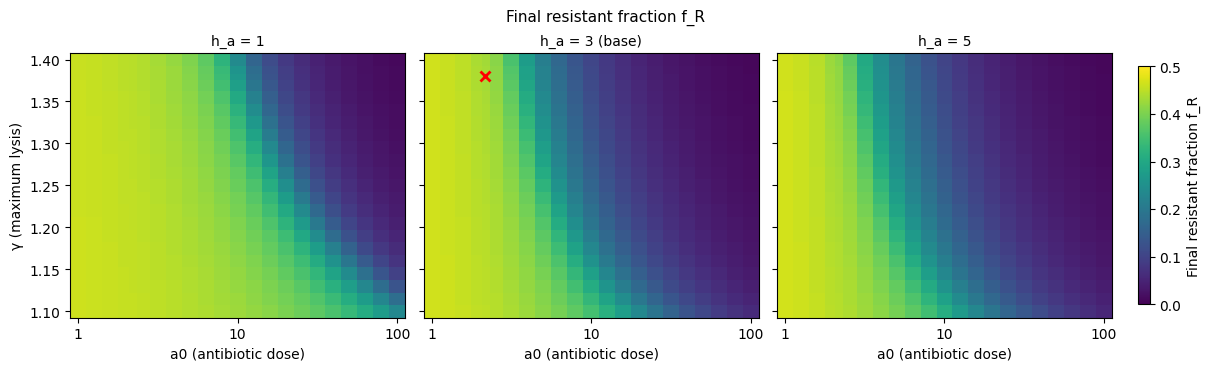

R gained (f_R rose above 0.5) in 0 of 10,164 runs; final f_R ranges from 0.009 to 0.466


In [4]:
SL = [1.0, 3.0, 5.0]
heatmap_slices(df, "a0", "gamma", "f_R_final", "h_a", SL, vmin=0, vmax=0.5); plt.show()
print(f"R gained (f_R rose above 0.5) in {(df.delta_log_ratio > 0).sum()} of {len(df):,} runs; "
      f"final f_R ranges from {df.f_R_final.min():.3f} to {df.f_R_final.max():.3f}")

## Depth of the crash

Left to right the dose rises by two orders of magnitude, so the lowest densities are shown on a log
scale. The extinction floor (one cell) is 4.4 × 10⁻⁹, i.e. about −8.4 on these maps.

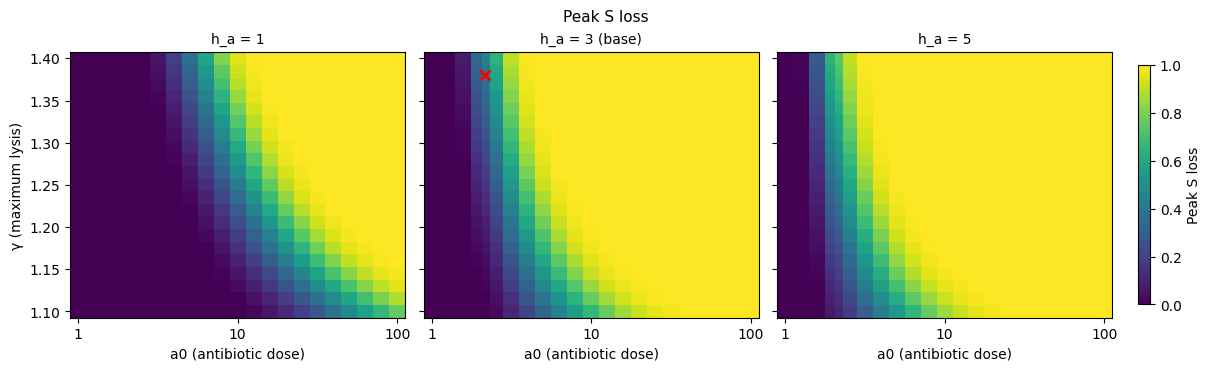

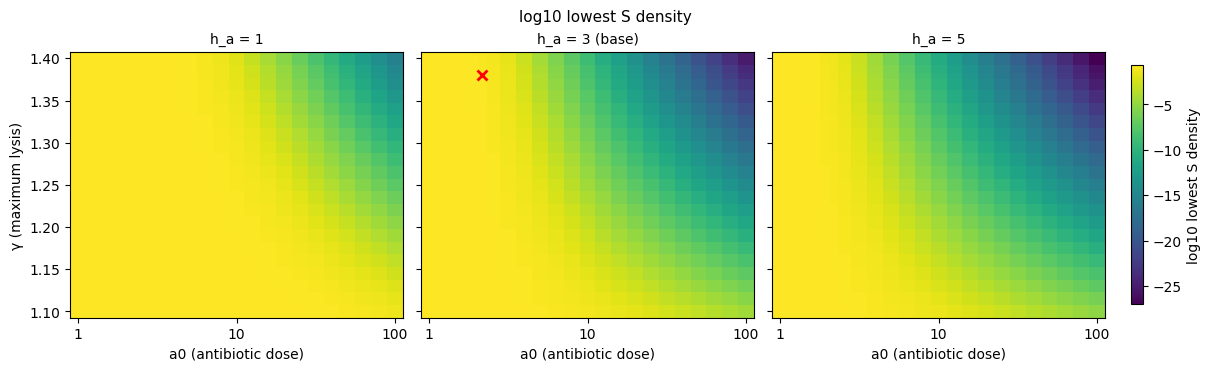

In [5]:
heatmap_slices(df, "a0", "gamma", "peak_loss_S", "h_a", SL, vmin=0, vmax=1); plt.show()
heatmap_slices(df, "a0", "gamma", "log10_ns_min", "h_a", SL, title="log10 lowest S density"); plt.show()

### The killing threshold

S only declines while lysis exceeds growth, i.e. while a > a* = (γ − 1)^(−1/h_a). A dose below a*
causes no loss at all. This is checked against every run in the grid.

Runs with a0 <= a*: 1,536; runs with zero S loss: 1,536; the two sets are identical: True
a* ranges from 1.20 to 10.00 over the grid; at the base point a* = 1.38 (the Fig. 2C dose is 2.15)


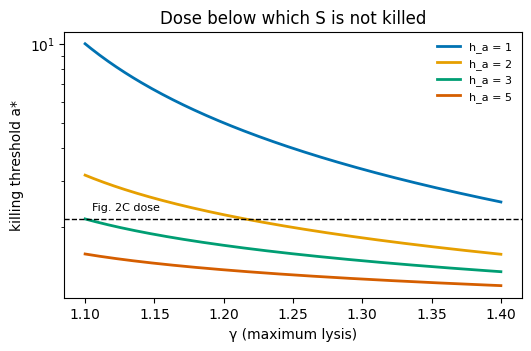

In [6]:
a_star = (df.gamma - 1) ** (-1 / df.h_a)
no_loss = df.peak_loss_S == 0
below = df.a0 <= a_star * (1 + 1e-6)          # tolerance: three grid doses equal a* exactly
print(f"Runs with a0 <= a*: {below.sum():,}; runs with zero S loss: {no_loss.sum():,}; "
      f"the two sets are identical: {bool((below == no_loss).all())}")
assert (below == no_loss).all()
print(f"a* ranges from {a_star.min():.2f} to {a_star.max():.2f} over the grid; at the base point a* = "
      f"{(BASE_VALUES['gamma'] - 1) ** (-1 / BASE_VALUES['h_a']):.2f} (the Fig. 2C dose is 2.15)")
g = np.linspace(1.1, 1.4, 200)
fig, ax = plt.subplots(figsize=(5.2, 3.4), constrained_layout=True)
for h, col in zip((1, 2, 3, 5), (OKABE_ITO["blue"], OKABE_ITO["orange"], OKABE_ITO["green"], OKABE_ITO["vermillion"])):
    ax.semilogy(g, (g - 1) ** (-1 / h), color=col, lw=2, label=f"h_a = {h}")
ax.axhline(BASE_A0, color="black", ls="--", lw=1); ax.text(1.105, BASE_A0 * 1.08, "Fig. 2C dose", fontsize=8)
ax.set(xlabel=label("gamma"), ylabel="killing threshold a*", title="Dose below which S is not killed"); ax.legend(frameon=False, fontsize=8)
plt.show()

## Recovery and settling times

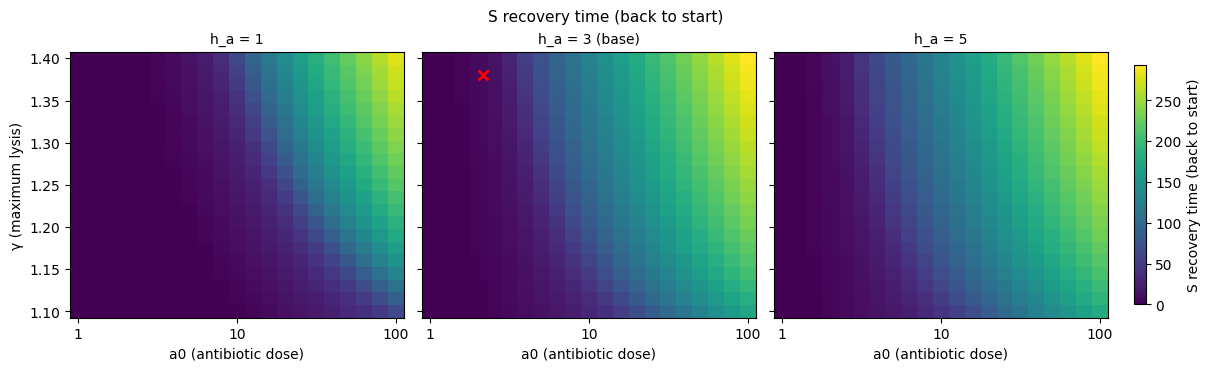

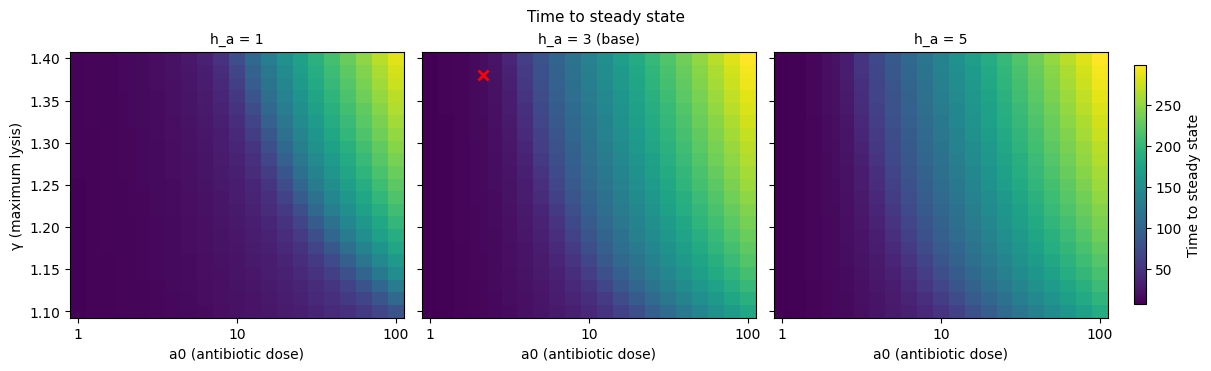

In [7]:
heatmap_slices(df, "a0", "gamma", "t_regain_S", "h_a", SL); plt.show()
heatmap_slices(df, "a0", "gamma", "t_steady_state", "h_a", SL); plt.show()

## Dose response across the grid

Median over all γ and h_a (line) with the 10-90% range (band).

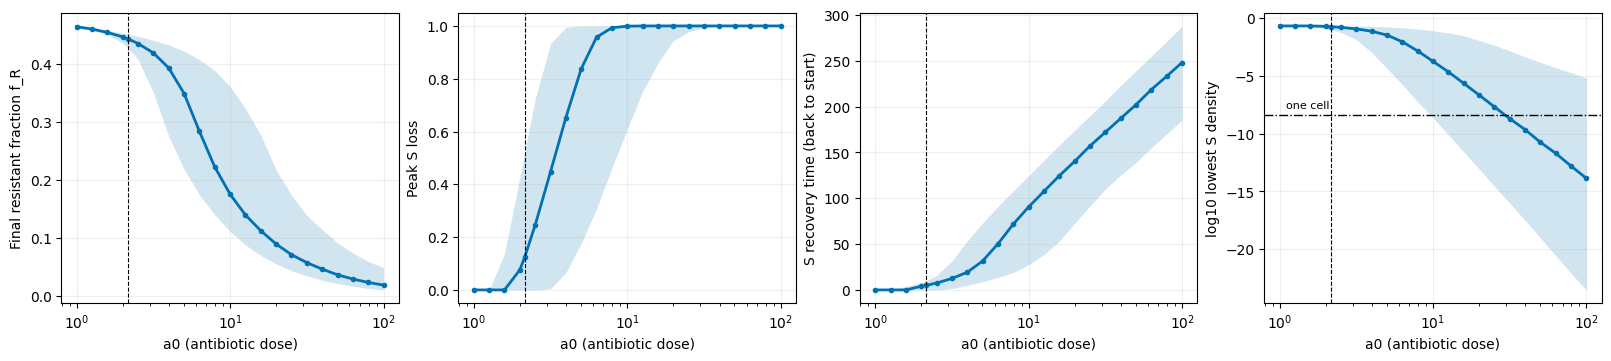

,f_R_final,peak_loss_S,t_regain_S,t_steady_state
a0,,,,
1.000000,0.464,0.000,0.00,7.00
1.995262,0.446,0.076,4.00,12.00
3.162278,0.419,0.447,12.50,19.50
6.309573,0.283,0.957,50.25,58.00
12.589254,0.139,1.000,107.50,115.25
25.118864,0.071,1.000,157.00,164.00
50.118723,0.036,1.000,202.00,210.00
100.000000,0.018,1.000,248.00,255.00


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
for ax, col in zip(axes, ["f_R_final", "peak_loss_S", "t_regain_S", "log10_ns_min"]):
    g = df.groupby("a0")[col]
    ax.fill_between(g.median().index, g.quantile(0.1), g.quantile(0.9), color=OKABE_ITO["blue"], alpha=0.18, lw=0)
    ax.plot(g.median().index, g.median(), color=OKABE_ITO["blue"], lw=2, marker="o", ms=3)
    ax.set_xscale("log"); ax.set(xlabel=label("a0"), ylabel=label(col)); ax.grid(alpha=0.2)
    ax.axvline(BASE_A0, color="black", ls="--", lw=0.8)
axes[3].axhline(np.log10(engine.EXTINCTION_FLOOR), color="black", ls="-.", lw=1)
axes[3].text(1.1, np.log10(engine.EXTINCTION_FLOOR) + 0.5, "one cell", fontsize=8)
plt.show()
df.groupby("a0")[["f_R_final", "peak_loss_S", "t_regain_S", "t_steady_state"]].median().round(3).iloc[::3]

## What happens once the extinction floor is applied

In the plain model every run regrows. With the floor, a population that falls below one cell is gone.
The stacked bars show, for each dose, the share of (γ, h_a) combinations in each outcome.

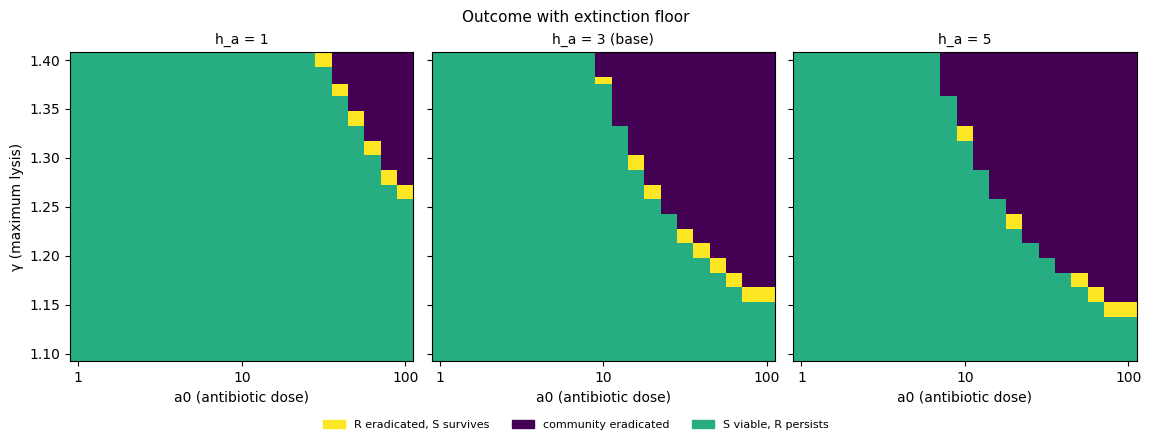

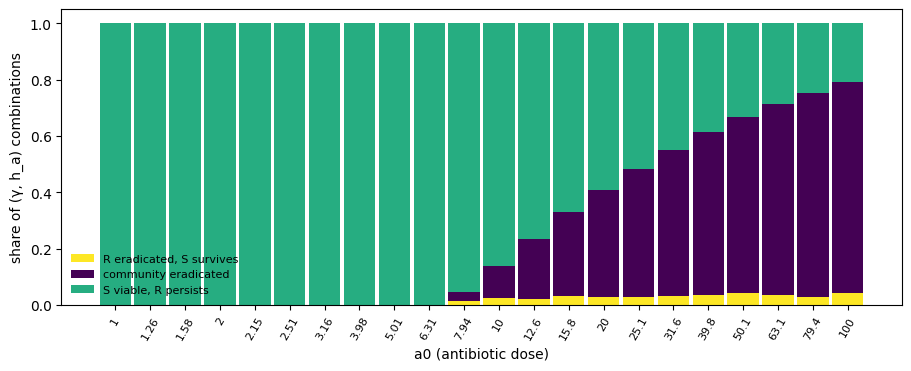

R eradicated while S survives: 172 runs (1.7%); lowest dose at which it happens: a0 = 7.94
In those runs the lowest S is only 1.7x the floor (median), and the lowest R is 0.54x the floor
Across the grid the lowest S is 1.63x the lowest R (median; range 1.00-7.12)


In [9]:
outcome_map(df, "a0", "gamma", "h_a", SL); plt.show()
share = pd.crosstab(df.a0, df.outcome_floor, normalize="index")
order = [o for o in engine.OUTCOME_FLOOR_ORDER if o in share.columns]
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
bottom = np.zeros(len(share))
for o in order:
    ax.bar(range(len(share)), share[o], bottom=bottom, color=OUTCOME_COLORS[o], label=o, width=0.9)
    bottom += share[o].values
ax.set_xticks(range(len(share))); ax.set_xticklabels([f"{v:.3g}" for v in share.index], rotation=60, fontsize=8)
ax.set(xlabel=label("a0"), ylabel="share of (γ, h_a) combinations"); ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.show()
goal = df[df.goal_met_floor]
print(f"R eradicated while S survives: {len(goal)} runs ({len(goal) / len(df):.1%}); lowest dose at which it happens: a0 = {goal.a0.min():.3g}")
print(f"In those runs the lowest S is only {np.median(goal.ns_min / engine.EXTINCTION_FLOOR):.1f}x the floor (median), "
      f"and the lowest R is {np.median(goal.nr_min / engine.EXTINCTION_FLOOR):.2f}x the floor")
print(f"Across the grid the lowest S is {np.median(df.ns_min / df.nr_min):.2f}x the lowest R (median; range "
      f"{(df.ns_min / df.nr_min).min():.2f}-{(df.ns_min / df.nr_min).max():.2f})")

## γ and h_a at the Fig. 2C dose (a0 = 2.15)

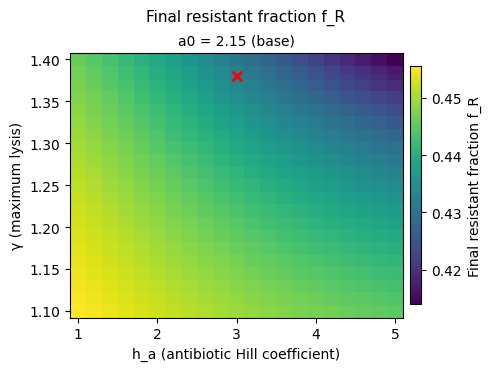

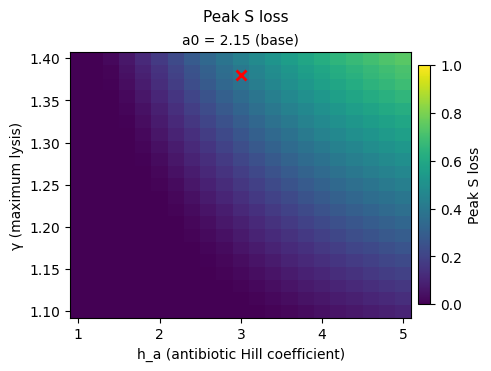

At a0 = 2.15: f_R from 0.414 to 0.456; peak S loss from 0.0% to 74.1%


In [10]:
heatmap_slices(df, "h_a", "gamma", "f_R_final", "a0", [BASE_A0]); plt.show()
heatmap_slices(df, "h_a", "gamma", "peak_loss_S", "a0", [BASE_A0], vmin=0, vmax=1); plt.show()
sl = select(df, {"a0": BASE_A0})
print(f"At a0 = 2.15: f_R from {sl.f_R_final.min():.3f} to {sl.f_R_final.max():.3f}; peak S loss from {sl.peak_loss_S.min():.1%} to {sl.peak_loss_S.max():.1%}")

## Effect of each parameter

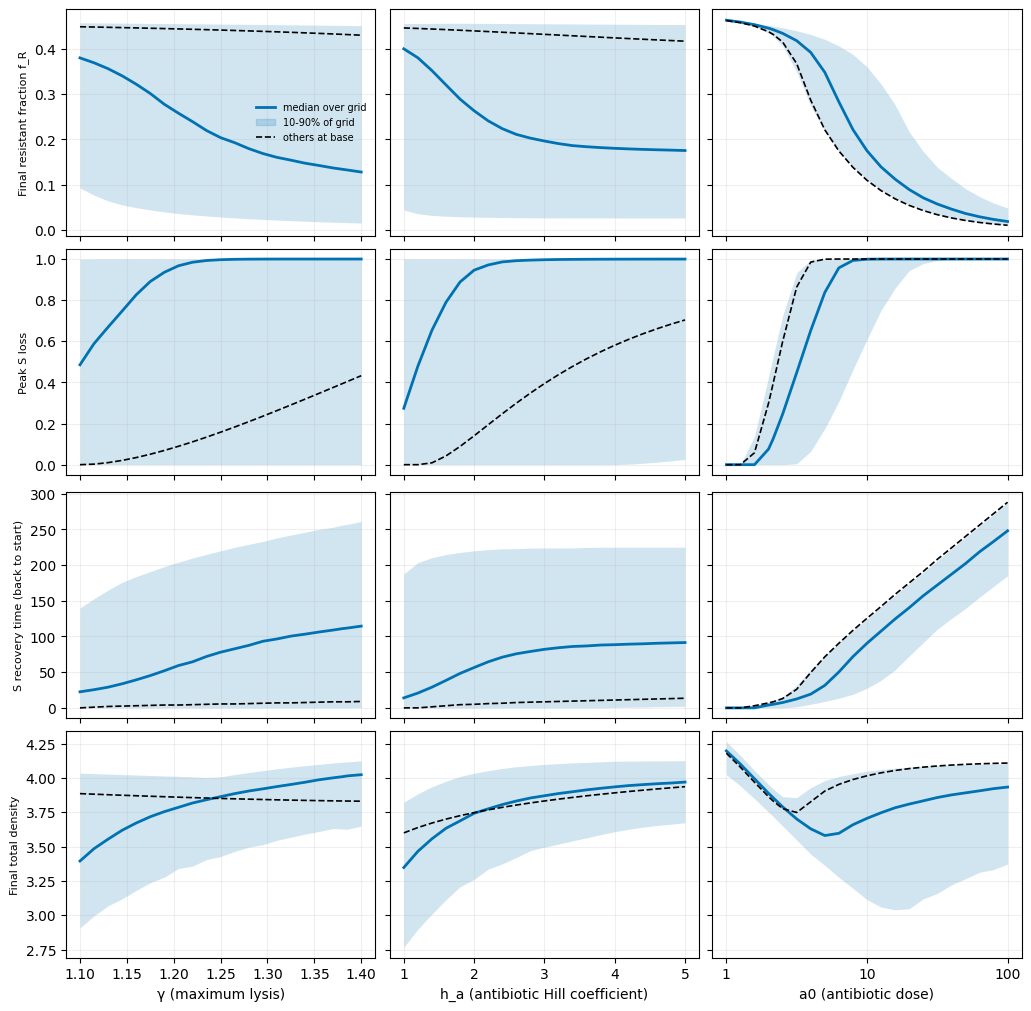

In [11]:
marginal_effects(df, PARAMS, ["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]); plt.show()

## Example time courses (base parameters, rising dose; dash-dot line = one cell)

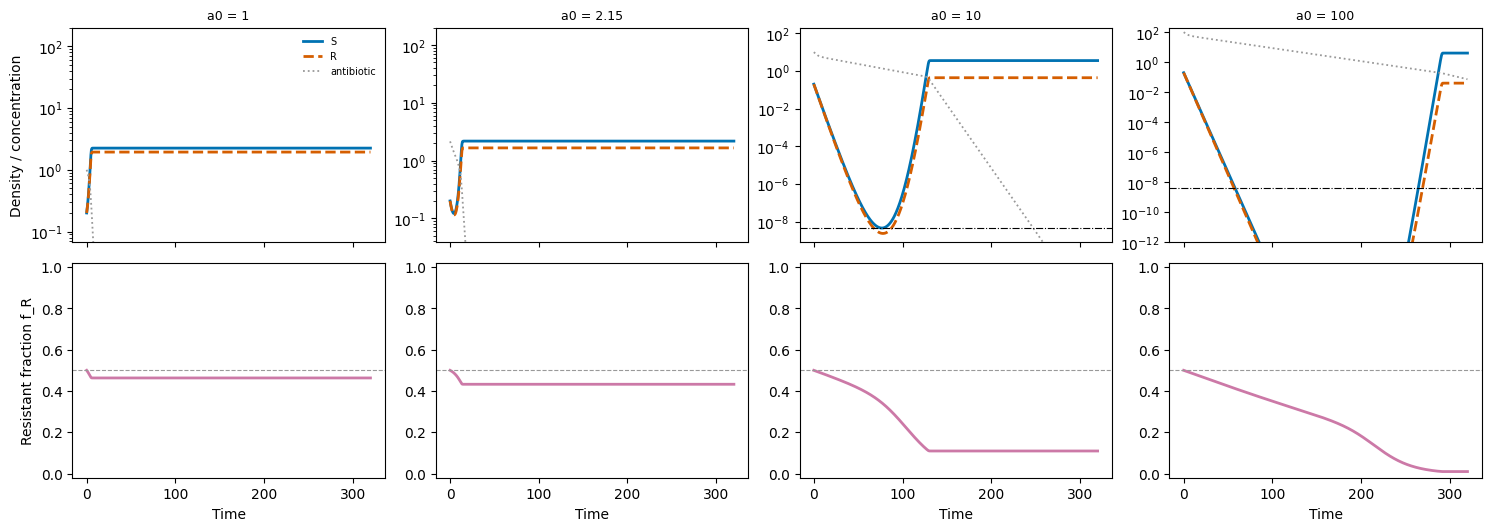

In [12]:
timecourses([(f"a0 = {a:g}", {"a0": a}) for a in (1.0, 2.15, 10.0, 100.0)], t_end=320); plt.show()

## Rank sensitivity over the whole grid

In [13]:
ends = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "t_regain_S", "t_steady_state"]
rho = pd.DataFrame({label(e): [settled[[p, e]].corr(method="spearman").iloc[0, 1] for p in PARAMS] for e in ends},
                   index=[SHORT[p] for p in PARAMS])
print("Spearman rank correlation between each parameter and each endpoint, over the whole grid:")
rho.round(2)

Spearman rank correlation between each parameter and each endpoint, over the whole grid:


,Final resistant fraction f_R,Final Shannon diversity H,Final total density,Peak S loss,S recovery time (back to start),Time to steady state
γ,-0.22,-0.22,0.47,0.31,0.22,0.21
h_a,-0.11,-0.11,0.49,0.22,0.15,0.10
a0,-0.96,-0.96,-0.15,0.88,0.95,0.96


## Takeaways

- **Dose dominates.** The rank correlation between a0 and final f_R is −0.96; the median f_R falls from
  0.46 at a0 = 1 to 0.018 at a0 = 100. γ and h_a have weak overall effects (−0.22 and −0.11).
- **The direction of selection never reverses.** With the base resistance traits and i = 10, S gains in
  every one of the 10,164 runs (f_R between 0.009 and 0.466).
- **There is a sharp killing threshold.** S loses nothing unless a0 exceeds a* = (γ − 1)^(−1/h_a); this
  holds exactly for every run. a* is 1.38 at base and ranges from 1.2 to 10 over the grid. γ and
  h_a move this threshold, and above it γ sets the net kill rate (γ·H(a) − 1 per unit growth), which
  changes the depth of the crash by about 20 orders of magnitude at a0 = 100.
- **At the Fig. 2C dose, γ and h_a change the crash, not the composition:** f_R only moves between
  0.414 and 0.456 while peak S loss ranges from 0% to 74%.
- **High doses mean extreme bottlenecks and long recoveries.** At base γ and h_a, the lowest S density
  is 5 × 10⁻⁹ at a0 = 10 and 2 × 10⁻²⁴ at a0 = 100, and S needs about 126 and 288 time units to get back to
  its starting density. 35% of runs needed a horizon beyond t = 150.
- **The plain model always regrows; with the extinction floor it does not.** In the plain model every
  run ends "S viable, R persists". With the floor, 24.4% of runs end with the whole community
  eradicated (from a0 ≈ 8 upwards; 75% of the (γ, h_a) plane at a0 = 100).
- **Dose alone cannot remove R selectively.** "R eradicated, S survives" occurs in only 1.7% of runs,
  as a band one grid dose wide along the eradication boundary. S and R crash almost together: in those
  runs the lowest S is only about 3.6 times the lowest R (median), which leaves S about 1.7 times above
  the floor. The gap grows slowly with dose (median ratio about 2 at a0 = 10 and 5 at a0 = 100) while
  both populations fall by many orders of magnitude. Whether the resistance traits (α, β_min, c) widen
  the window is tested in notebook 08.